# Free Recall Overnight Sentiment Shift: Day 2 Pre vs. Day 1 Post

This notebook analyzes the **overnight consolidation shift** in free-recall sentiment from the end of Day 1 (**Day 1 Post**) to the beginning of Day 2 (**Day 2 Pre**, prior to the memory test):

1. **Full Sample Analysis ($N = 64$):**
   - **Pos $-$ Neg Sentiment Delta:** `DeltaDay2Pre` vs. `DeltaDay1Post`
   - **Positive Sentiment:** `day_2_pre_pos` vs. `day_1_post_pos`
   - **Negative Sentiment:** `day_2_pre_neg` vs. `day_1_post_neg`
   - **Compound Sentiment:** `day_2_pre_compound` vs. `day_1_post_compound`
   - Paired $t$-tests and continuous correlations (Pearson & Spearman) with `GAD-7`.

2. **Extreme Anxiety Groups (`Low: GAD-7 < 4` vs. `High: GAD-7 > 10`):**
   - $2 \times 2$ Mixed ANOVAs (`Group` $\times$ `Time [Day 1 Post vs. Day 2 Pre]`).
   - Group trajectory visualizations and correlations within the extreme groups.

3. **Clinical Severity Sensitivity & Power Analysis (`GAD-7 > 10`, `> 12`, and `>= 15` vs. `< 4`):**
   - Effect sizes (Cohen's $d$) and required sample sizes per group for $80\%$ and $90\%$ power.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [2]:
# Load and merge NLP free-recall sentiment and GAD-7 survey data
df_nlp = pd.read_csv('../data/free_recall_nlp.csv')
df_survey = pd.read_csv('../data/survey.csv')
df_merged = pd.merge(df_nlp, df_survey, on='Sub', how='inner')

cols_to_numeric = [
    'day_1_pre_pos', 'day_1_pre_neg', 'day_1_pre_compound',
    'day_1_post_pos', 'day_1_post_neg', 'day_1_post_compound',
    'day_2_pre_pos', 'day_2_pre_neg', 'day_2_pre_compound',
    'day_2_post_pos', 'day_2_post_neg', 'day_2_post_compound',
    'GAD7'
]
for col in cols_to_numeric:
    df_merged[col] = pd.to_numeric(df_merged[col], errors='coerce')

# Pos - Neg Deltas at each timepoint
df_merged['DeltaDay1Pre'] = df_merged['day_1_pre_pos'] - df_merged['day_1_pre_neg']
df_merged['DeltaDay1Post'] = df_merged['day_1_post_pos'] - df_merged['day_1_post_neg']
df_merged['DeltaDay2Pre'] = df_merged['day_2_pre_pos'] - df_merged['day_2_pre_neg']

# Overnight shift variables (Day 2 Pre - Day 1 Post)
df_merged['Overnight_Delta'] = df_merged['DeltaDay2Pre'] - df_merged['DeltaDay1Post']
df_merged['Overnight_Pos'] = df_merged['day_2_pre_pos'] - df_merged['day_1_post_pos']
df_merged['Overnight_Neg'] = df_merged['day_2_pre_neg'] - df_merged['day_1_post_neg']
df_merged['Overnight_Comp'] = df_merged['day_2_pre_compound'] - df_merged['day_1_post_compound']

df_valid = df_merged.dropna(subset=['day_1_post_compound', 'day_2_pre_compound']).copy()
print(f"Total merged subjects: {len(df_merged)} | Complete for Day 1 Post & Day 2 Pre: {len(df_valid)}")


Total merged subjects: 67 | Complete for Day 1 Post & Day 2 Pre: 64


In [3]:
# 1. Full-Sample Paired t-tests & Correlations with GAD-7 (Day 2 Pre vs. Day 1 Post)
comparisons = [
    ('Overnight_Delta', 'DeltaDay2Pre', 'DeltaDay1Post', 'Pos - Neg Delta (Day 2 Pre vs Day 1 Post)'),
    ('Overnight_Pos', 'day_2_pre_pos', 'day_1_post_pos', 'Positive Sentiment (Day 2 Pre vs Day 1 Post)'),
    ('Overnight_Neg', 'day_2_pre_neg', 'day_1_post_neg', 'Negative Sentiment (Day 2 Pre vs Day 1 Post)'),
    ('Overnight_Comp', 'day_2_pre_compound', 'day_1_post_compound', 'Compound Score (Day 2 Pre vs Day 1 Post)')
]

t_rows = []
corr_rows = []
for diff_col, col_d2, col_d1, label in comparisons:
    sub = df_valid.dropna(subset=[col_d2, col_d1, diff_col, 'GAD7'])
    t_stat, p_val = stats.ttest_rel(sub[col_d2], sub[col_d1])
    d_z = pg.compute_effsize(sub[col_d2], sub[col_d1], paired=True, eftype='cohen')
    t_rows.append({
        'Metric': label,
        'N': len(sub),
        'Day 1 Post Mean': sub[col_d1].mean(),
        'Day 2 Pre Mean': sub[col_d2].mean(),
        'Mean Diff (D2Pre - D1Post)': sub[diff_col].mean(),
        'SD Diff': sub[diff_col].std(),
        't-stat': t_stat,
        'p-value': p_val,
        'Cohen d_z': d_z
    })
    r_p, p_p = stats.pearsonr(sub[diff_col], sub['GAD7'])
    r_s, p_s = stats.spearmanr(sub[diff_col], sub['GAD7'])
    corr_rows.append({
        'Metric': label,
        'N': len(sub),
        'Pearson r': r_p,
        'Pearson p': p_p,
        'Spearman r': r_s,
        'Spearman p': p_s
    })

df_t_full = pd.DataFrame(t_rows)
df_corr_full = pd.DataFrame(corr_rows)

print("=== FULL SAMPLE PAIRED T-TESTS: DAY 2 PRE vs. DAY 1 POST ===")
print(df_t_full.to_string(index=False))
print("\n=== FULL SAMPLE CORRELATIONS WITH GAD-7 (OVERNIGHT SHIFT) ===")
print(df_corr_full.to_string(index=False))


=== FULL SAMPLE PAIRED T-TESTS: DAY 2 PRE vs. DAY 1 POST ===
                                      Metric  N  Day 1 Post Mean  Day 2 Pre Mean  Mean Diff (D2Pre - D1Post)  SD Diff    t-stat  p-value  Cohen d_z
   Pos - Neg Delta (Day 2 Pre vs Day 1 Post) 64         0.049078        0.085422                    0.036344 0.139632  2.082256 0.041386   0.282354
Positive Sentiment (Day 2 Pre vs Day 1 Post) 64         0.140141        0.173078                    0.032938 0.092233  2.856897 0.005789   0.362182
Negative Sentiment (Day 2 Pre vs Day 1 Post) 64         0.091062        0.087656                   -0.003406 0.082789 -0.329149 0.743135  -0.046836
    Compound Score (Day 2 Pre vs Day 1 Post) 64         0.291759        0.332873                    0.041114 0.610339  0.538901 0.591854   0.074331

=== FULL SAMPLE CORRELATIONS WITH GAD-7 (OVERNIGHT SHIFT) ===
                                      Metric  N  Pearson r  Pearson p  Spearman r  Spearman p
   Pos - Neg Delta (Day 2 Pre vs Day 1 Pos

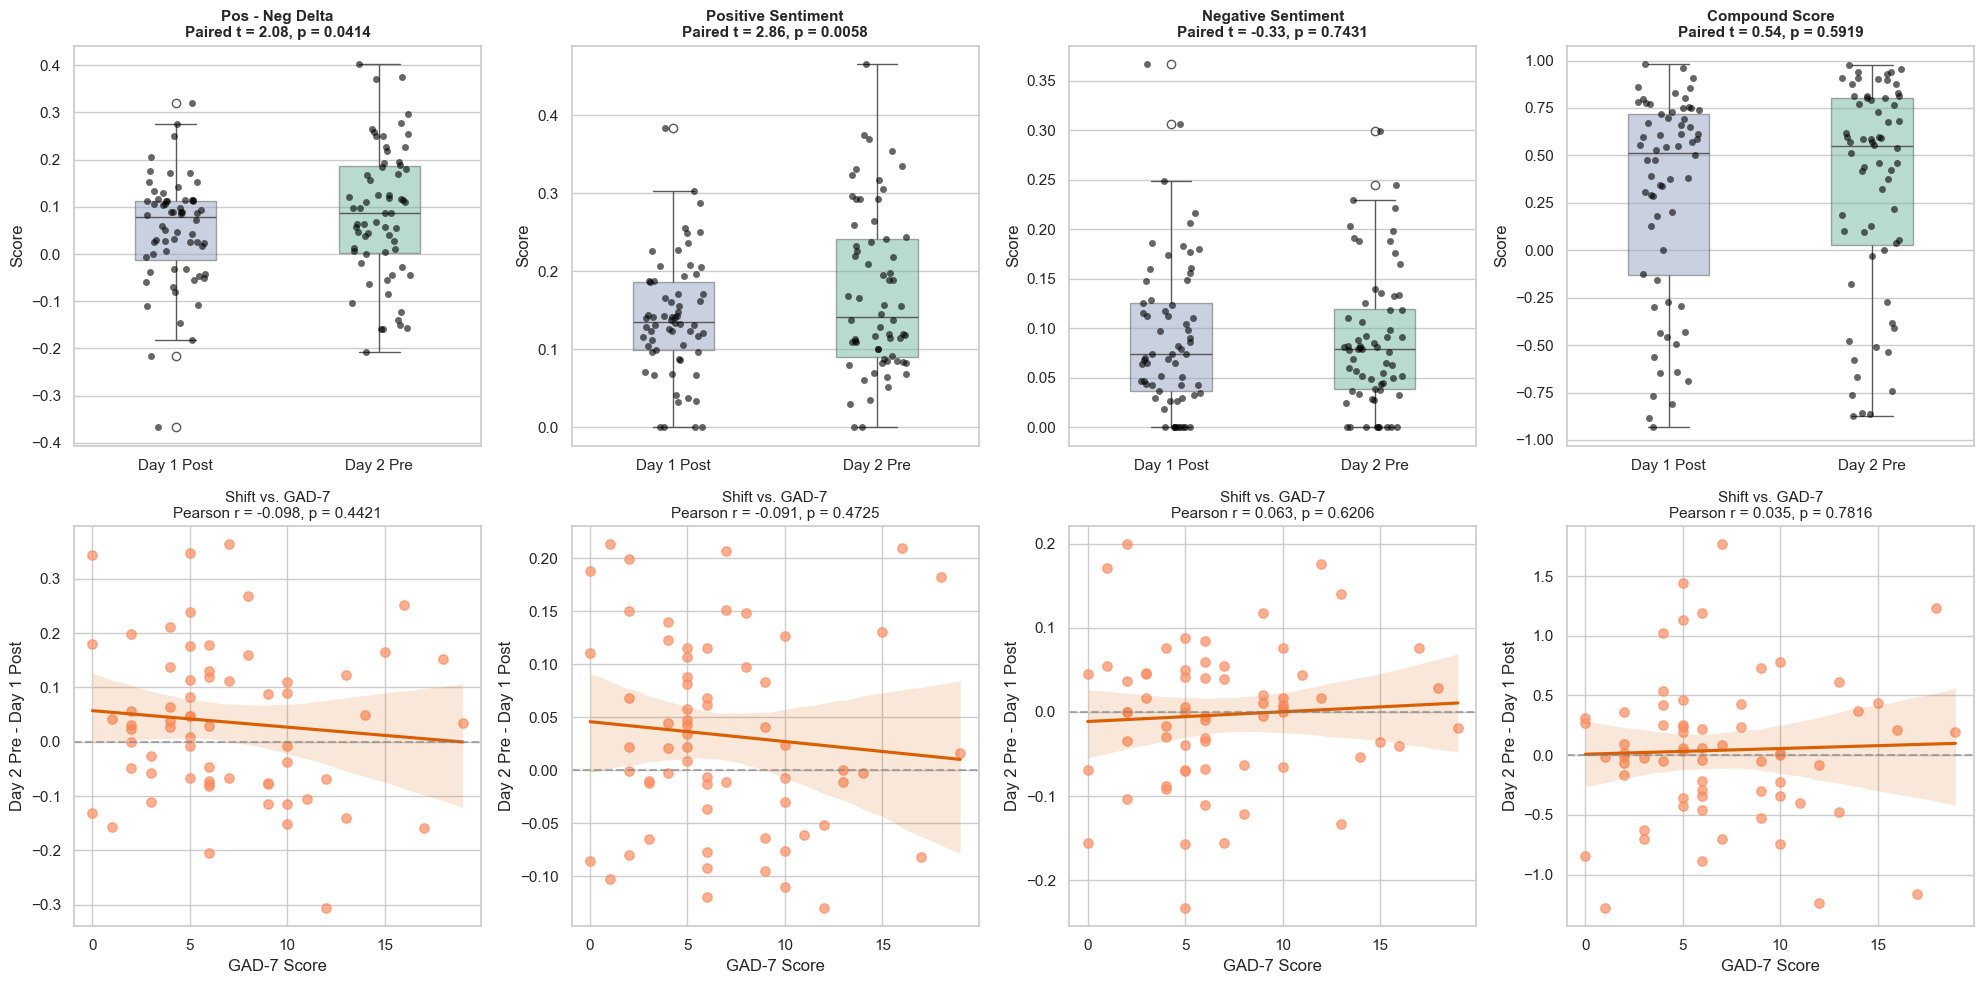

In [4]:
# Visualize Full-Sample Day 1 Post vs. Day 2 Pre Comparisons & GAD-7 Regressions
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for idx, (diff_col, col_d2, col_d1, label) in enumerate(comparisons):
    sub = df_valid.dropna(subset=[col_d2, col_d1, diff_col, 'GAD7'])
    
    # Top row: Box + Strip plot comparing Day 1 Post vs Day 2 Pre
    ax_top = axes[0, idx]
    melted = pd.melt(sub[['Sub', col_d1, col_d2]].rename(columns={col_d1: 'Day 1 Post', col_d2: 'Day 2 Pre'}),
                     id_vars='Sub', var_name='Timepoint', value_name='Score')
    sns.boxplot(data=melted, x='Timepoint', y='Score', ax=ax_top, width=0.4, palette=['#8da0cb', '#66c2a5'], boxprops=dict(alpha=0.5))
    sns.stripplot(data=melted, x='Timepoint', y='Score', ax=ax_top, color='black', alpha=0.6, jitter=0.15)
    t_stat, p_val = stats.ttest_rel(sub[col_d2], sub[col_d1])
    ax_top.set_title(f"{label.split(' (')[0]}\nPaired t = {t_stat:.2f}, p = {p_val:.4f}", fontsize=11, fontweight='bold')
    ax_top.set_xlabel("")
    
    # Bottom row: Regression of Overnight Shift against GAD-7
    ax_bot = axes[1, idx]
    sns.regplot(data=sub, x='GAD7', y=diff_col, ax=ax_bot, color='#fc8d62',
                scatter_kws={'alpha': 0.7, 's': 45}, line_kws={'color': '#d95f02'})
    ax_bot.axhline(0, color='gray', linestyle='--', alpha=0.6)
    r_p, p_p = stats.pearsonr(sub[diff_col], sub['GAD7'])
    ax_bot.set_title(f"Shift vs. GAD-7\nPearson r = {r_p:.3f}, p = {p_p:.4f}", fontsize=11)
    ax_bot.set_xlabel("GAD-7 Score")
    ax_bot.set_ylabel("Day 2 Pre - Day 1 Post")

plt.tight_layout()
plt.show()


In [5]:
# 2. Extreme Anxiety Groups Analysis (Low: GAD-7 < 4 vs. High: GAD-7 > 10)
df_ext = df_valid[(df_valid['GAD7'] < 4) | (df_valid['GAD7'] > 10)].copy()
df_ext['Anxiety_Group'] = np.where(df_valid.loc[df_ext.index, 'GAD7'] > 10, 'High (GAD-7 > 10)', 'Low (GAD-7 < 4)')

print(f"Extreme Groups Sample: Low (<4) n = {(df_ext['Anxiety_Group']=='Low (GAD-7 < 4)').sum()}, High (>10) n = {(df_ext['Anxiety_Group']=='High (GAD-7 > 10)').sum()}")

for diff_col, col_d2, col_d1, label in comparisons:
    print(f"\n==================================================================")
    print(f"MIXED ANOVA: {label}")
    print(f"==================================================================")
    long_df = pd.melt(
        df_ext,
        id_vars=['Sub', 'Anxiety_Group', 'GAD7'],
        value_vars=[col_d1, col_d2],
        var_name='Timepoint',
        value_name='Score'
    )
    aov = pg.mixed_anova(dv='Score', within='Timepoint', between='Anxiety_Group', subject='Sub', data=long_df)
    print(aov[['Source', 'SS', 'DF1', 'DF2', 'F', 'p_unc', 'np2']].to_string(index=False))
    
    for grp in ['Low (GAD-7 < 4)', 'High (GAD-7 > 10)']:
        g_df = df_ext[df_ext['Anxiety_Group'] == grp]
        t_g, p_g = stats.ttest_rel(g_df[col_d2], g_df[col_d1])
        print(f"  {grp:18s} | D1 Post = {g_df[col_d1].mean():+.4f} (SD={g_df[col_d1].std():.4f}) -> D2 Pre = {g_df[col_d2].mean():+.4f} (SD={g_df[col_d2].std():.4f}) | Diff = {g_df[diff_col].mean():+.4f} (t={t_g:.2f}, p={p_g:.4f})")


Extreme Groups Sample: Low (<4) n = 14, High (>10) n = 11

MIXED ANOVA: Pos - Neg Delta (Day 2 Pre vs Day 1 Post)
       Source       SS  DF1  DF2        F    p_unc      np2
Anxiety_Group 0.012646    1   23 0.466952 0.501219 0.019898
    Timepoint 0.002326    1   23 0.199833 0.659037 0.008614
  Interaction 0.001852    1   23 0.159112 0.693655 0.006870
  Low (GAD-7 < 4)    | D1 Post = +0.0841 (SD=0.0920) -> D2 Pre = +0.1086 (SD=0.1595) | Diff = +0.0244 (t=0.66, p=0.5203)
  High (GAD-7 > 10)  | D1 Post = +0.0644 (SD=0.1280) -> D2 Pre = +0.0643 (SD=0.1691) | Diff = -0.0001 (t=-0.00, p=0.9986)

MIXED ANOVA: Positive Sentiment (Day 2 Pre vs Day 1 Post)
       Source       SS  DF1  DF2        F    p_unc      np2
Anxiety_Group 0.002209    1   23 0.117593 0.734774 0.005087
    Timepoint 0.012577    1   23 2.030864 0.167563 0.081134
  Interaction 0.001824    1   23 0.294587 0.592517 0.012646
  Low (GAD-7 < 4)    | D1 Post = +0.1499 (SD=0.0565) -> D2 Pre = +0.1923 (SD=0.1323) | Diff = +0.0424 (t

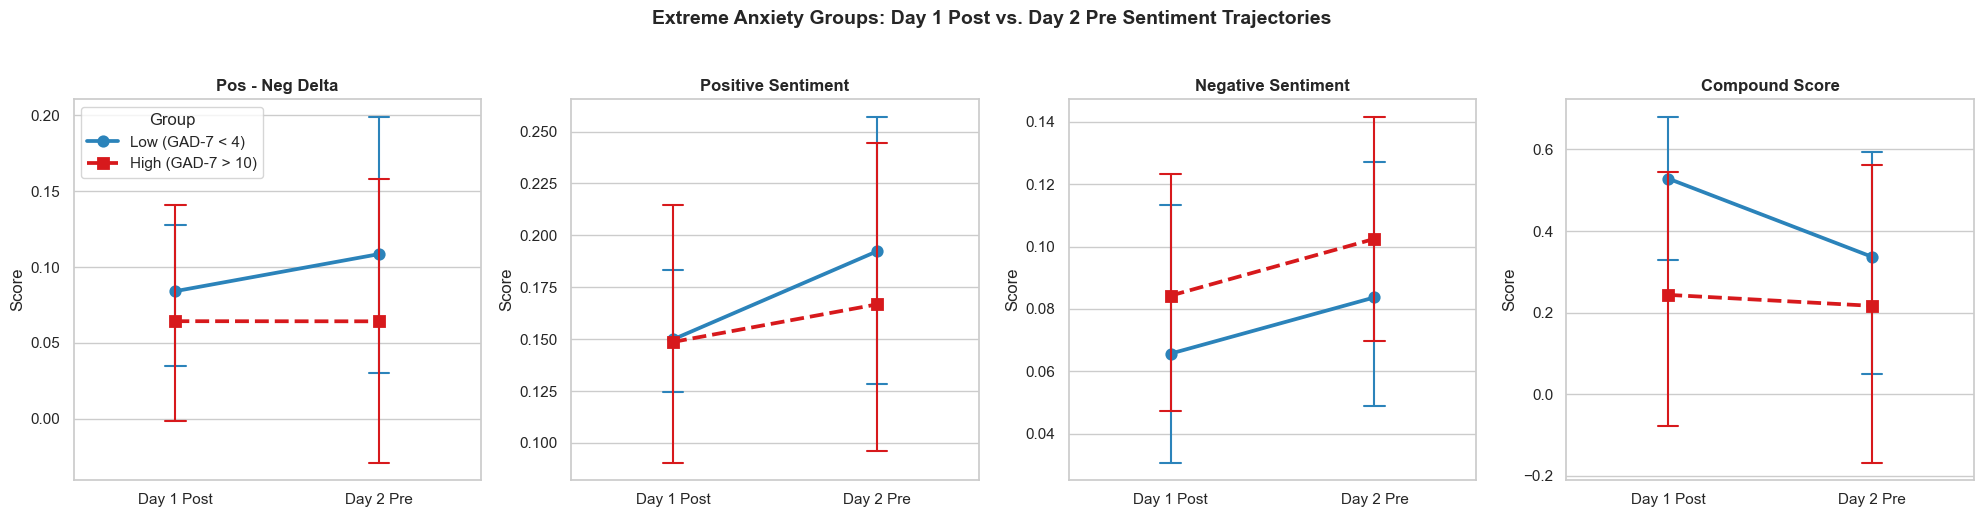

In [6]:
# Plot Extreme Group Trajectories from Day 1 Post to Day 2 Pre
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for idx, (diff_col, col_d2, col_d1, label) in enumerate(comparisons):
    ax = axes[idx]
    long_df = pd.melt(
        df_ext.rename(columns={col_d1: 'Day 1 Post', col_d2: 'Day 2 Pre'}),
        id_vars=['Sub', 'Anxiety_Group'],
        value_vars=['Day 1 Post', 'Day 2 Pre'],
        var_name='Timepoint',
        value_name='Score'
    )
    sns.pointplot(
        data=long_df, x='Timepoint', y='Score', hue='Anxiety_Group',
        hue_order=['Low (GAD-7 < 4)', 'High (GAD-7 > 10)'],
        palette=['#2b83ba', '#d7191c'], markers=['o', 's'], linestyles=['-', '--'],
        capsize=0.1, err_kws={'linewidth': 1.5}, ax=ax
    )
    ax.set_title(label.split(' (')[0], fontsize=12, fontweight='bold')
    ax.set_xlabel("")
    if idx > 0:
        ax.get_legend().remove()
    else:
        ax.legend(title="Group", loc='best')

plt.suptitle("Extreme Anxiety Groups: Day 1 Post vs. Day 2 Pre Sentiment Trajectories", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


In [7]:
# 3. Clinical Severity Sensitivity & Sample Size Power Analysis (Compound Sentiment: Day 2 Pre vs. Day 1 Post)
power_rows = []
g_low = df_valid[df_valid['GAD7'] < 4]

for thresh_label, thresh_val in [('High (GAD-7 > 10)', 10), ('Clinical (GAD-7 > 12)', 12), ('Severe (GAD-7 >= 15)', 14)]:
    g_high = df_valid[df_valid['GAD7'] > thresh_val]
    
    # Interaction effect size (difference in overnight compound change)
    d_inter = abs(pg.compute_effsize(g_low['Overnight_Comp'], g_high['Overnight_Comp'], eftype='cohen'))
    n80_2t = np.ceil(pg.power_ttest(d=d_inter, power=0.80, alpha=0.05, contrast='two-samples'))
    n80_1t = np.ceil(pg.power_ttest(d=d_inter, power=0.80, alpha=0.05, contrast='two-samples', alternative='greater'))
    n90_2t = np.ceil(pg.power_ttest(d=d_inter, power=0.90, alpha=0.05, contrast='two-samples'))
    
    power_rows.append({
        'High Group Cutoff': thresh_label,
        'n_Low (<4)': len(g_low),
        'n_High': len(g_high),
        'Low Shift (D2Pre-D1Post)': g_low['Overnight_Comp'].mean(),
        'High Shift (D2Pre-D1Post)': g_high['Overnight_Comp'].mean(),
        'Cohen d (Interaction)': d_inter,
        'N/group (80% 2-tailed)': int(n80_2t),
        'N/group (80% 1-tailed)': int(n80_1t),
        'N/group (90% 2-tailed)': int(n90_2t)
    })

df_power = pd.DataFrame(power_rows)
print("=== POWER ANALYSIS: COMPOUND SENTIMENT OVERNIGHT SHIFT (DAY 2 PRE - DAY 1 POST) ===")
print(df_power.to_string(index=False))


=== POWER ANALYSIS: COMPOUND SENTIMENT OVERNIGHT SHIFT (DAY 2 PRE - DAY 1 POST) ===
    High Group Cutoff  n_Low (<4)  n_High  Low Shift (D2Pre-D1Post)  High Shift (D2Pre-D1Post)  Cohen d (Interaction)  N/group (80% 2-tailed)  N/group (80% 1-tailed)  N/group (90% 2-tailed)
    High (GAD-7 > 10)          14      11                 -0.191807                  -0.026909               0.268933                     219                     172                     292
Clinical (GAD-7 > 12)          14       8                 -0.191807                   0.177162               0.636913                      40                      32                      53
 Severe (GAD-7 >= 15)          14       5                 -0.191807                   0.181400               0.625317                      42                      33                      55
